In [1]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
sys.path.append("../../../")
from helper_function import *
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_harrisleft.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)
gem2seed = pd.read_csv('../../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')

OD = pd.read_excel('../../../Expression_datasets/harris_nm/harriswang_nbt_cleaned.xlsx', sheet_name='OD')
expression_data = pd.read_excel('../../../Expression_datasets/harris_nm/harriswang_nbt_cleaned.xlsx', sheet_name='Expression_data')

In [3]:
def species_gpr_construction(model):
    species_gpr = []
    for rec in model.reactions:
        if len(rec.genes) > 0:
            gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
            species_gpr.append((rec.id.split('_')[:-1][0], gene_id))
    species_gpr = pd.DataFrame(species_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

    return species_gpr

In [4]:
def species_clustergenes_construction(species_gpr):
    cluster_genes = {}
    for idx, group in cluster_nodes.items():
        for rec in group:
            rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
            rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
            if rec2seed is not None:
                rec2gene = species_gpr[species_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
                rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
                if rec2gene is not None:
                    if idx not in cluster_genes:
                        cluster_genes[idx] = []
                    for gene in rec2gene:
                        cluster_genes[idx].append(gene)

    return cluster_genes

In [5]:
def species_ei_construction(species_trans_data, cluster_genes):
    n_samples = len(OD.columns) - 1
    overall_value = np.zeros((len(cluster_nodes), n_samples)) 

    for idx, group in cluster_genes.items():

        group_value = np.zeros(n_samples)

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue
            gene_value = np.array(gene_value[0]) / gene_count

            # 累加到该 cluster
            group_value += gene_value

        overall_value[idx, :] = group_value

    norm_overall_value = overall_value / np.sum(overall_value, axis=0)

    return norm_overall_value, overall_value

def species_sector_entropy_construction(species_trans_data, cluster_genes):
    n_samples = len(OD.columns) - 1
    overall_entropy = np.zeros((len(cluster_nodes), n_samples)) 


    for idx, group in cluster_genes.items():

        group_entropy = np.zeros(n_samples)

        temp = []

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue

            gene_value = np.array(gene_value[0]) / gene_count
            
            temp.append(gene_value)

            temp_array = np.array(temp)

            p = temp_array / np.sum(temp_array, axis=0, keepdims=True)

            group_entropy = -np.sum(p * np.log2(p + 1e-12), axis=0)

        overall_entropy[idx, :] = group_entropy


    return overall_entropy


def species_rec_expression_construction(species_trans_data, cluster_genes, species_gpr, overall_value):
    n_samples = len(OD.columns) - 1
    #overall_value = np.zeros((len(cluster_nodes), n_samples)) 

    rec_expression = {}

    for idx, group in cluster_genes.items():

        temp = {}

        group_value = np.zeros(n_samples)

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue
            gene_value = np.array(gene_value[0]) / gene_count / np.sum(overall_value, axis=0)

            rec_seed = [key for key, value in species_gpr.iloc if gene in value]
            rec_name = [gem2seed[gem2seed['SEED_Reaction_ID'] == key]['Model_Reaction_ID'].values[0] for key in rec_seed if key in gem2seed['SEED_Reaction_ID'].values]

            for rec in rec_name:
                if rec not in temp:
                    temp[rec] = np.zeros(n_samples)
                temp[rec] += gene_value / len(rec_name)

        rec_expression[idx] = temp

    return rec_expression

In [6]:
def species_detail_rec_expression_construction(species_trans_data, cluster_genes, species_gpr, overall_value):
    df = []
    for idx, group in cluster_nodes.items():
        for rec in group:
            rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
            rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
            if rec2seed is not None:
                rec2gene = species_gpr[species_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
                rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
                
                if rec2gene is None:
                    continue
                
                expression = 0
                for gene in rec2gene:
                    gene_count = sum(gene in g for g in cluster_genes.values())

                    gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

                    if gene_value.size == 0:
                        continue

                    gene_value = np.array(gene_value[0]) / gene_count / np.sum(overall_value, axis=0)

                    expression += gene_value

                df.append((rec, rec2gene, idx, expression))
    return pd.DataFrame(df, columns=['Reaction', 'Gene', 'Cluster', 'Expression'])

In [7]:
total_species_id = []
total_species_ei = []
total_species_sector_entropy = []
total_species_etotal = []
total_species_OD = []
total_species_cluster_genes = []
total_species_rec_expression = []
total_species_detail_rec_expression = []

temp = []


for i in range(len(OD)):
    species_id = OD.iloc[i]['Strain']
    species_OD = OD.iloc[i][1:].values #(#samples)

    species_model = cobra.io.read_sbml_model(f'../../../Expression_datasets/harris_nm/gem/{species_id}.xml')
    species_gpr = species_gpr_construction(species_model)

    species_cluster_genes = species_clustergenes_construction(species_gpr)

    species_trans_data = expression_data[expression_data['strain'] == species_id]

    species_ei, _ = species_ei_construction(species_trans_data, species_cluster_genes) #(Ei, #samples)

    species_sector_entropy = species_sector_entropy_construction(species_trans_data, species_cluster_genes)

    species_detail_rec_expression = species_detail_rec_expression_construction(species_trans_data, species_cluster_genes, species_gpr, _)

    #species_rec_expression = species_rec_expression_construction(species_trans_data, species_cluster_genes, species_gpr, _)

    total_species_id.append(species_id)
    total_species_ei.append(species_ei)
    total_species_OD.append(species_OD)
    total_species_etotal.append(np.sum(_, axis=0)/1e6)
    total_species_sector_entropy.append(species_sector_entropy)
    total_species_cluster_genes.append(species_cluster_genes)
    total_species_detail_rec_expression.append(species_detail_rec_expression)
    #total_species_rec_expression.append(species_rec_expression)

'' is not a valid SBML 'SId'.
/tmp/ipykernel_405902/96137535.py:52: RuntimeWarning: invalid value encountered in divide
  p = temp_array / np.sum(temp_array, axis=0, keepdims=True)
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.


In [8]:
env_index = -1
reaction_to_cluster = {
    rxn: cid
    for cid, rxns in cluster_nodes.items()
    for rxn in rxns
}

species_expr = {}
for i, df in enumerate(total_species_detail_rec_expression):
    species_name = f"Species_{i+1}"
    expr_dict = {}
    for _, row in df.iterrows():
        expr_list = row["Expression"]
        expr_value = expr_list[env_index] if env_index < len(expr_list) else 0.0
        expr_dict[row["Reaction"]] = expr_value
    species_expr[species_name] = expr_dict

all_reactions = sorted(set().union(*[d.keys() for d in species_expr.values()]))

rows = []
for rxn in all_reactions:
    row = {"Reaction": rxn}
    row["Cluster"] = reaction_to_cluster.get(rxn, "Unknown")
    for sp, expr_dict in species_expr.items():
        row[sp] = expr_dict.get(rxn, 0.0)
    rows.append(row)

combined_df = pd.DataFrame(rows)

species_cols = [c for c in combined_df.columns if c.startswith("Species_")]
combined_df = combined_df[["Reaction", "Cluster"] + species_cols]

In [9]:
from scipy.stats import spearmanr

species_cols = [c for c in combined_df.columns if c.startswith("Species_")] 
od_env = np.array(OD)[:, 1:][:, env_index] 

corrs = []
for _, row in combined_df.iterrows():
    expr = row[species_cols].astype(float).values 
    corr, _ = spearmanr(expr, od_env)  
    corrs.append(abs(corr))  

combined_df["Corr"] = corrs  


cluster_corrs = []  
for cluster_id, group in combined_df.groupby("Cluster"):
    expr_sum = group[species_cols].sum(axis=0).values 
    corr, _ = spearmanr(expr_sum, od_env)
    cluster_corrs.append(corr)

cluster_summary = combined_df.groupby("Cluster")["Corr"].agg(["var"])

n_perm = 10000  
random_means = []  
random_vars = []   

for _ in range(n_perm):
    shuffled = np.random.permutation(combined_df["Cluster"]) 
    tmp = combined_df.copy()
    tmp["Cluster"] = shuffled 
    agg = tmp.groupby("Cluster").apply(
        lambda group: abs(spearmanr(group[species_cols].sum(axis=0).values, od_env)[0])
    )
    random_means.append(agg.mean())  
    agg2 = tmp.groupby("Cluster")["Corr"].agg(["var"])
    
    random_vars.append(agg2["var"].mean())

obs_mean = abs(np.array(cluster_corrs)).mean()
obs_var = cluster_summary["var"].mean()

Observed Mean: 0.4404, p-value: 0.0143, z-score: 2.21


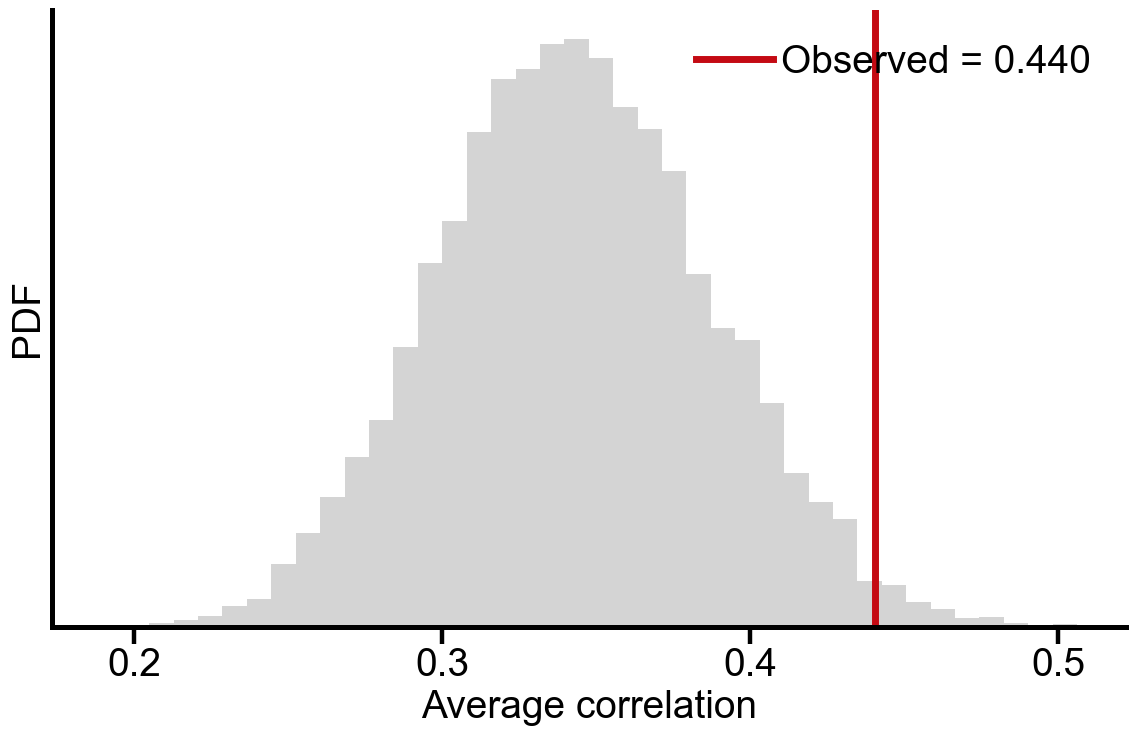

In [10]:
from matplotlib.ticker import MaxNLocator
set_panel_style(scale=4)
hist_color = "#D0D0D0"   # light gray
mean_line  = "#C40A13"   # deep red
var_line   = "#2F5597"   # deep blue

p_mean = (np.sum(np.array(random_means) >= obs_mean) + 1) / (n_perm + 1)
p_var  = (np.sum(np.array(random_vars)  <= obs_var)  + 1) / (n_perm + 1)
z_mean = (obs_mean - np.mean(random_means)) / np.std(random_means)
print(f"Observed Mean: {obs_mean:.4f}, p-value: {p_mean:.4f}, z-score: {z_mean:.2f}")

fig, ax = plt.subplots(figsize=(12, 8))

ax.hist(random_means, bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(obs_mean, color=mean_line, linewidth=5,
           label=rf"Observed = {obs_mean:.3f}")

ax.set_xlabel("Average correlation")
ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.tick_params(axis="y", left=False, labelleft=False)

ax.xaxis.set_major_locator(MaxNLocator(nbins=4))

plt.tight_layout()
plt.show()